In [1]:
# Basic data handling
import pandas as pd
import numpy as np
from imblearn.combine import SMOTEENN

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns


# Sklearn utilities
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Sklearn models
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# Metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    RocCurveDisplay
)

# Optuna for hyperparameter tuning
import optuna
from optuna.integration import OptunaSearchCV

# TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam, RMSprop
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset


from pytorch_tabular import TabularModel
from pytorch_tabular.models.category_embedding.config import CategoryEmbeddingModelConfig
from pytorch_tabular.config import DataConfig, TrainerConfig, OptimizerConfig
import optuna

# Warnings
import warnings
warnings.filterwarnings('ignore')


c:\Users\Louis Bernal\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### Data Exploration

In [2]:
df = pd.read_csv('bank-additional-full.csv', sep =';')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [4]:
df.describe(include= 'all')

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
count,41188.00000,41188,41188,41188,41188,41188,41188,41188,41188,41188,...,41188.000000,41188.000000,41188.000000,41188,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188
unique,NaN,12,4,8,3,3,3,2,10,5,...,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,2
top,NaN,admin.,married,university.degree,no,yes,no,cellular,may,thu,...,NaN,NaN,NaN,nonexistent,NaN,NaN,NaN,NaN,NaN,no
freq,NaN,10422,24928,12168,32588,21576,33950,26144,13769,8623,...,NaN,NaN,NaN,35563,NaN,NaN,NaN,NaN,NaN,36548
mean,40.02406,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.567593,962.475454,0.172963,NaN,0.081886,93.575664,-40.502600,3.621291,5167.035911,NaN
std,10.42125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.770014,186.910907,0.494901,NaN,1.570960,0.578840,4.628198,1.734447,72.251528,NaN
min,17.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.000000,0.000000,0.000000,NaN,-3.400000,92.201000,-50.800000,0.634000,4963.600000,NaN
25%,32.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.000000,999.000000,0.000000,NaN,-1.800000,93.075000,-42.700000,1.344000,5099.100000,NaN
50%,38.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.000000,999.000000,0.000000,NaN,1.100000,93.749000,-41.800000,4.857000,5191.000000,NaN
75%,47.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.000000,999.000000,0.000000,NaN,1.400000,93.994000,-36.400000,4.961000,5228.100000,NaN


In [5]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(12)

In [7]:
df.drop_duplicates(inplace = True)

#### Data Visualization

Text(0.5, 1.0, 'Target Distribution')

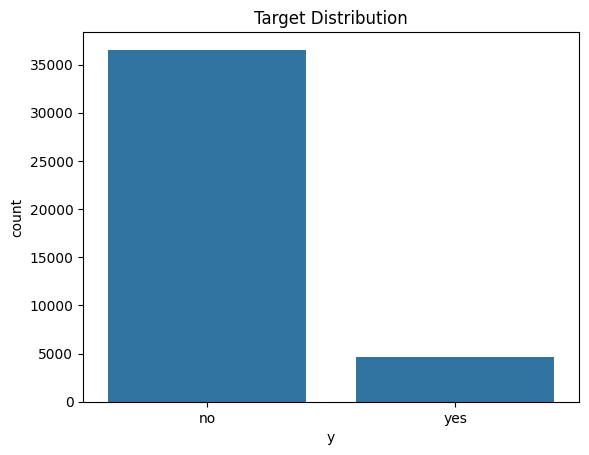

In [8]:
sns.countplot(data = df, x ='y')
plt.title('Target Distribution')

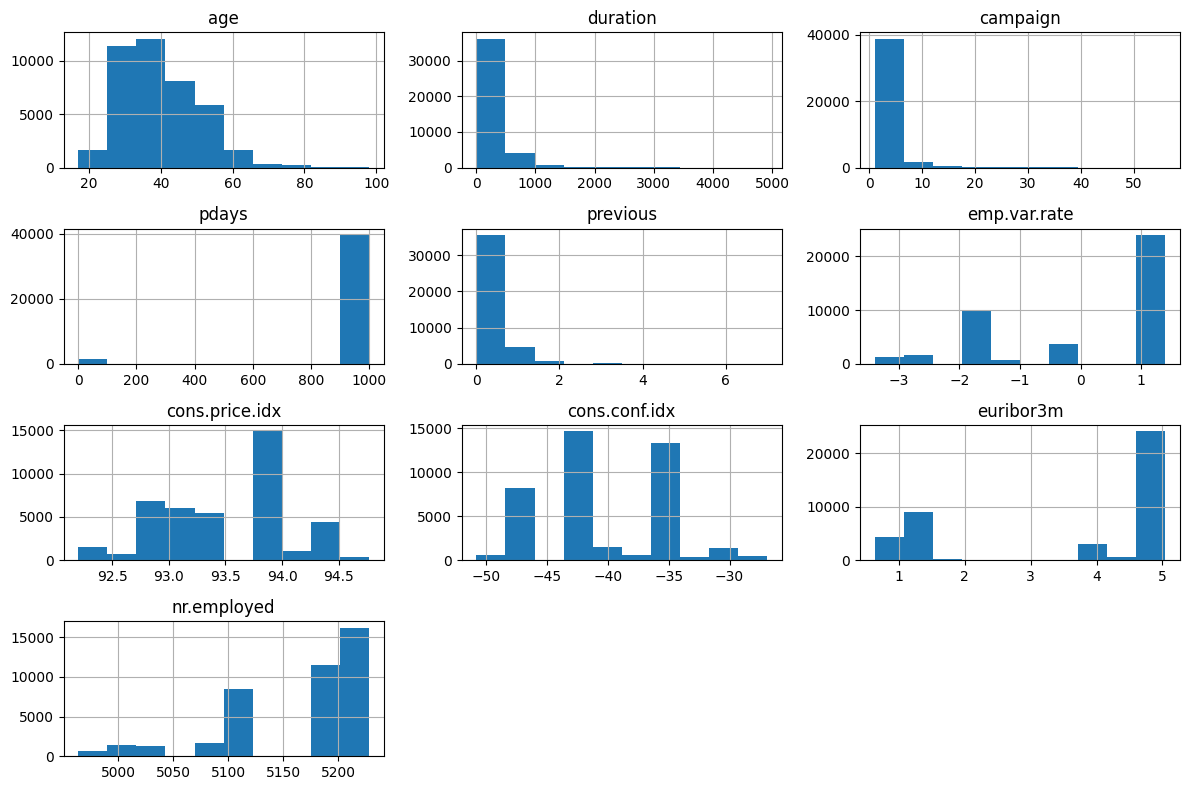

In [9]:
df.hist(figsize = (12, 8))
plt.tight_layout()

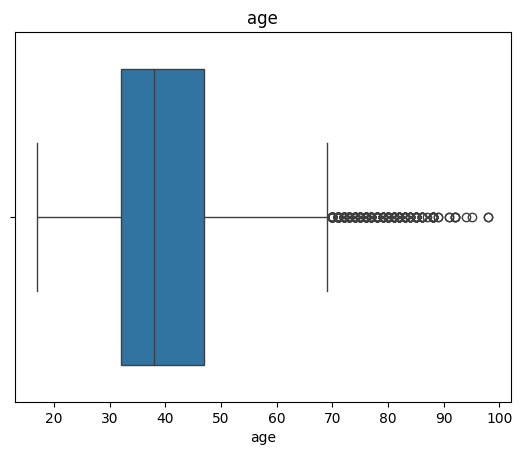

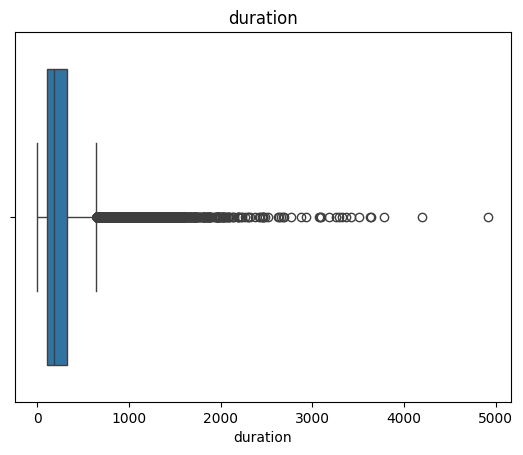

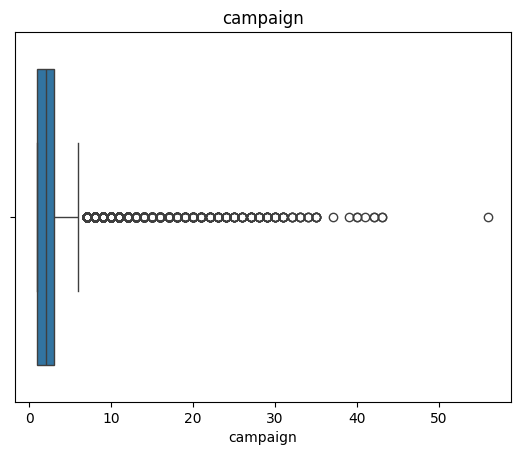

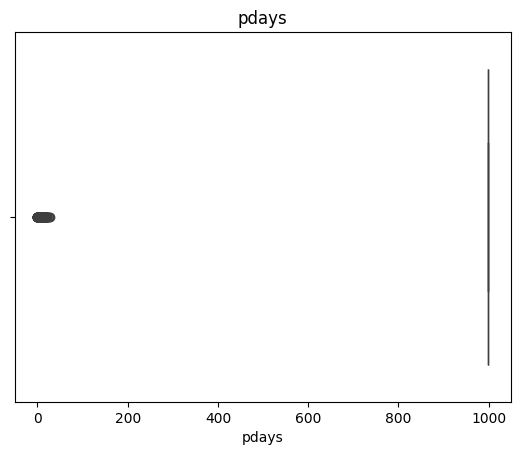

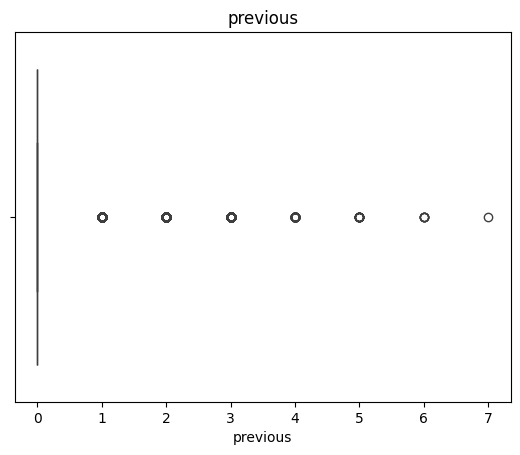

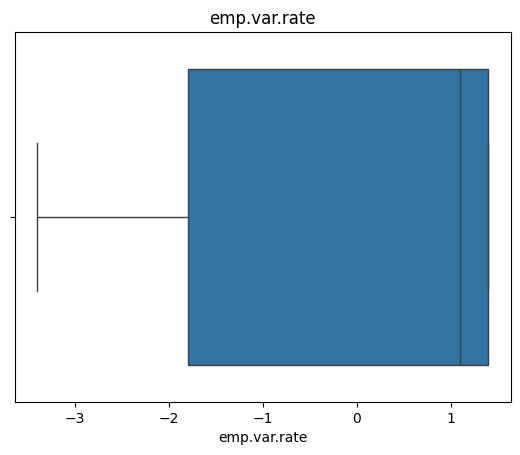

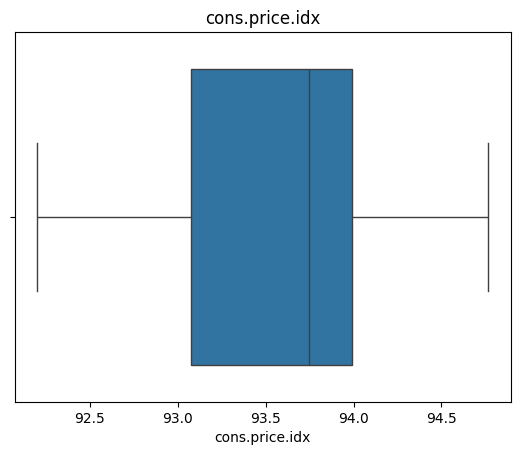

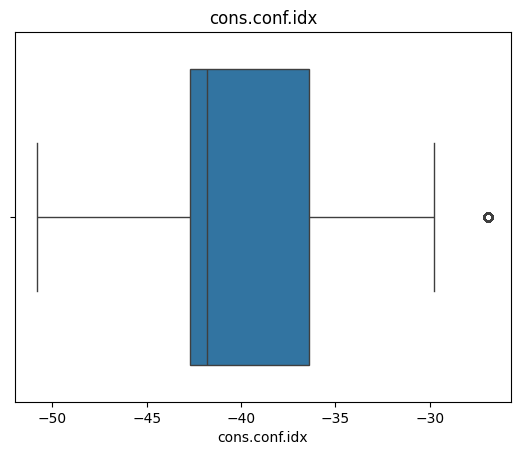

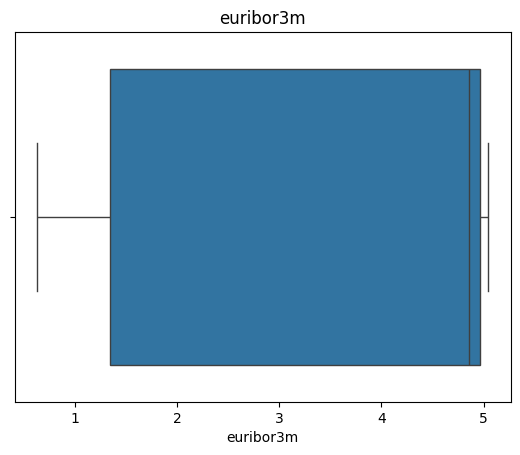

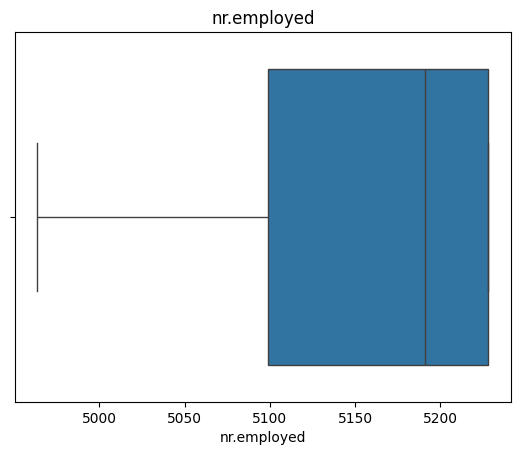

In [10]:
num_cols = df.select_dtypes(include= ['int64','float64'])

for col in num_cols:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()


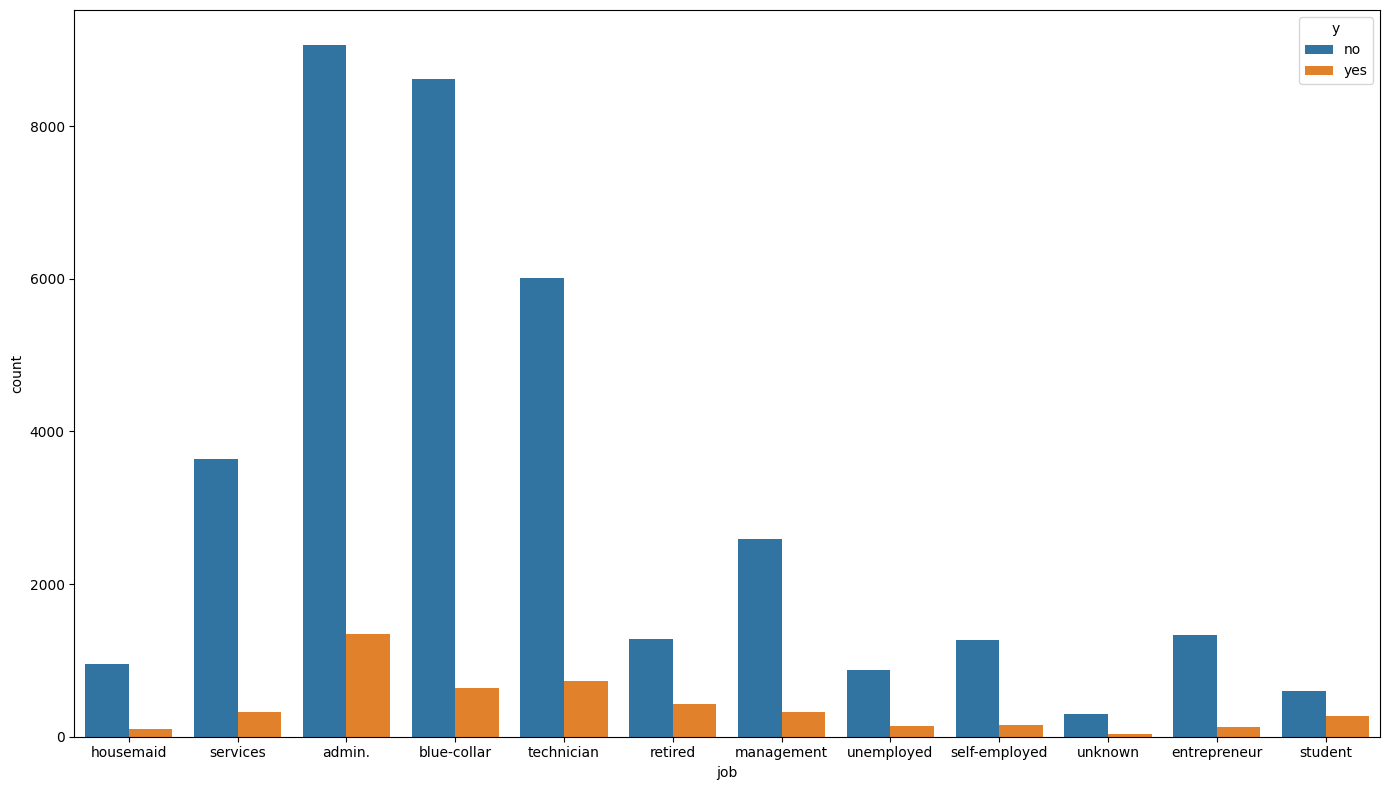

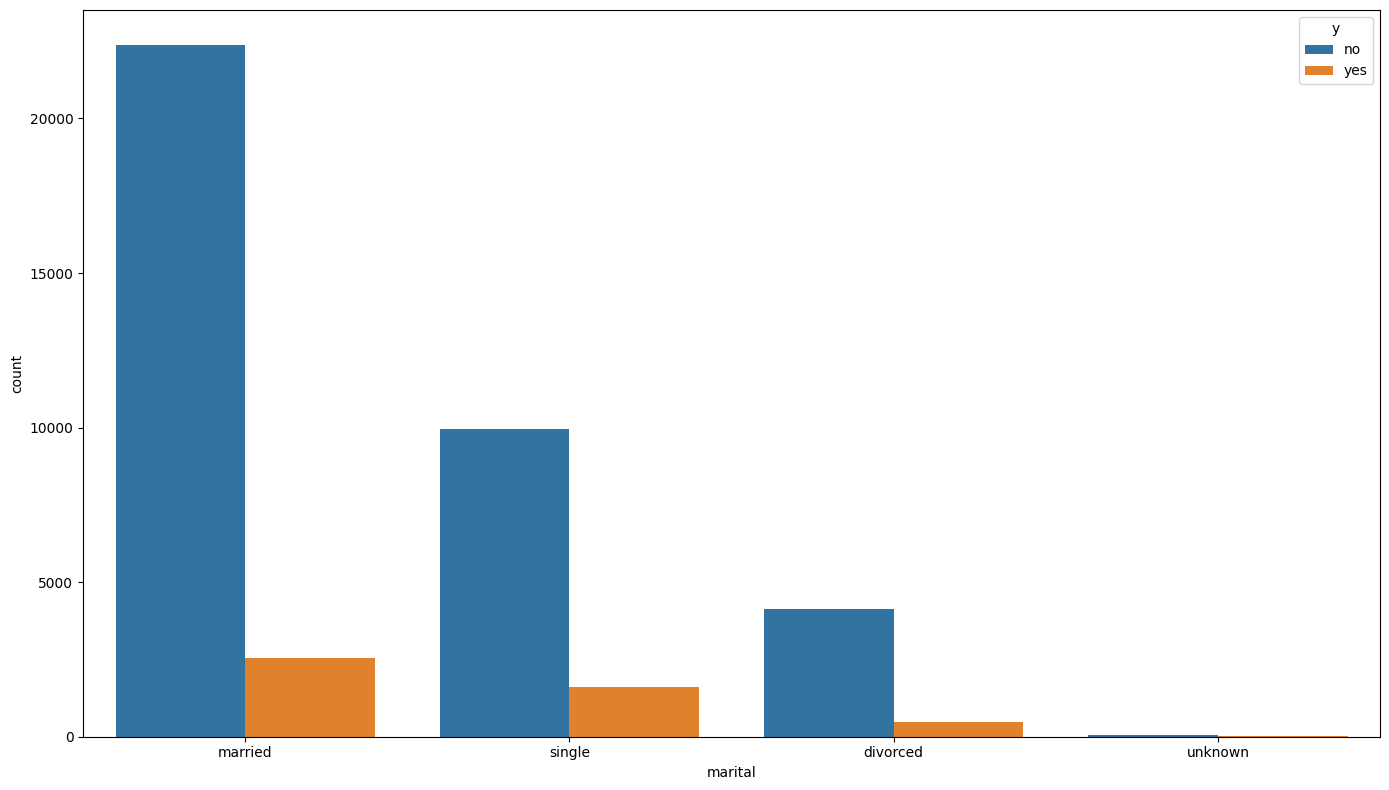

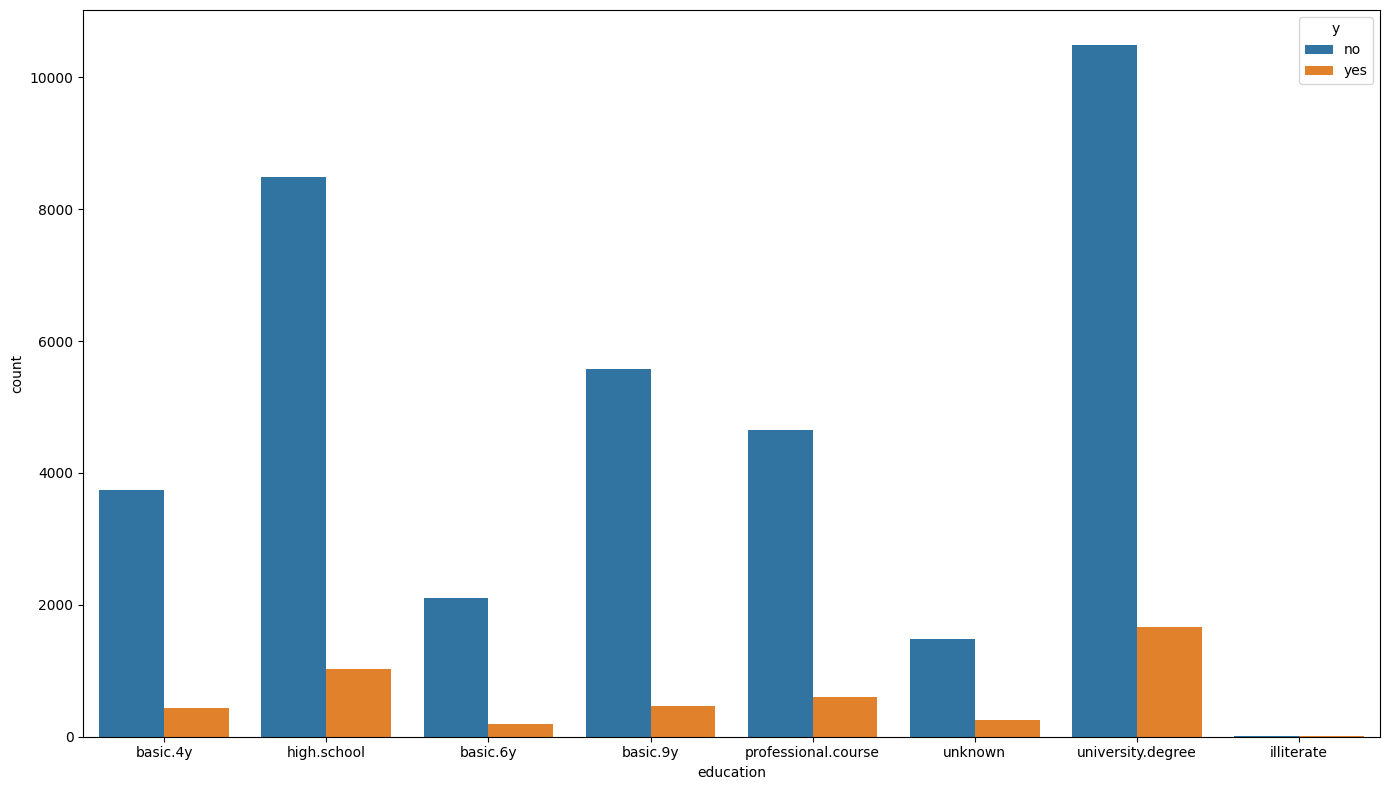

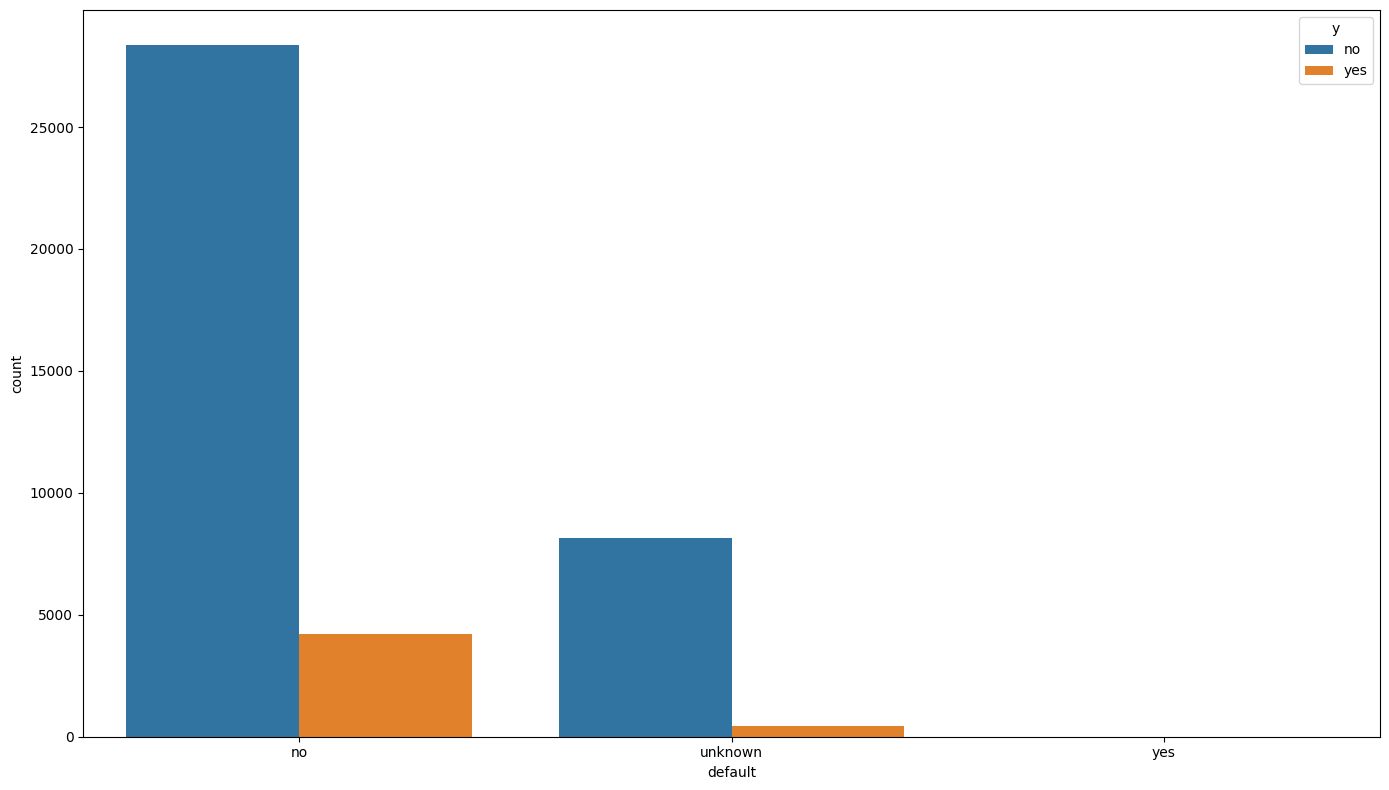

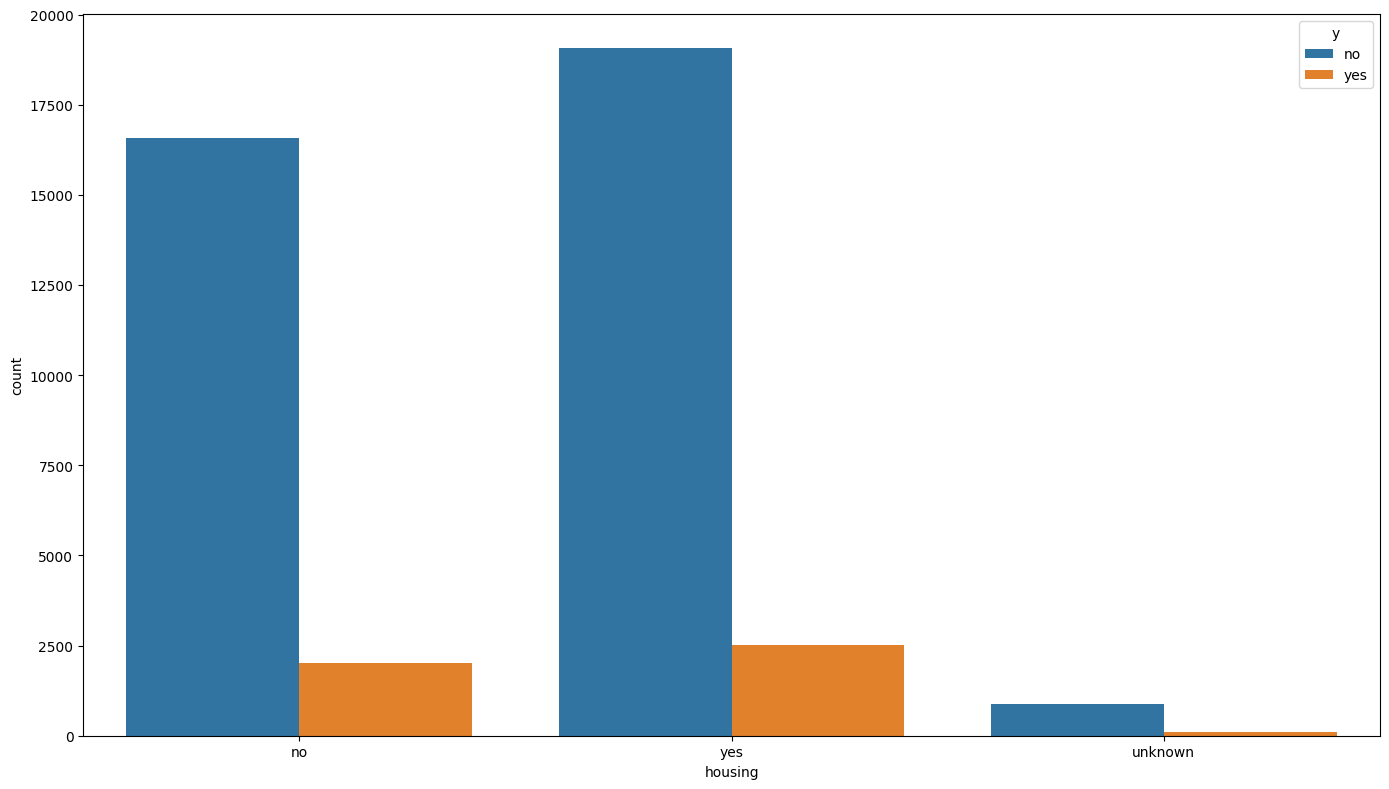

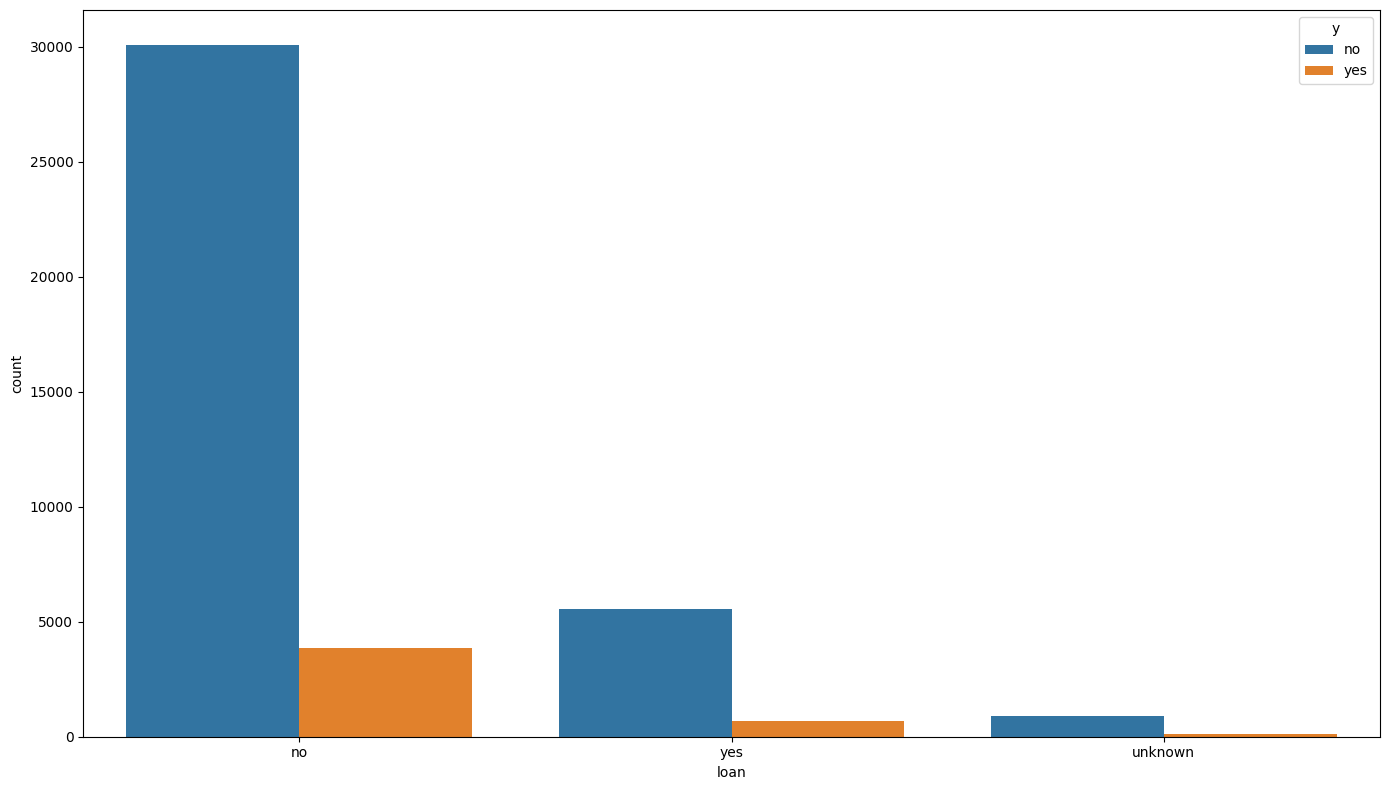

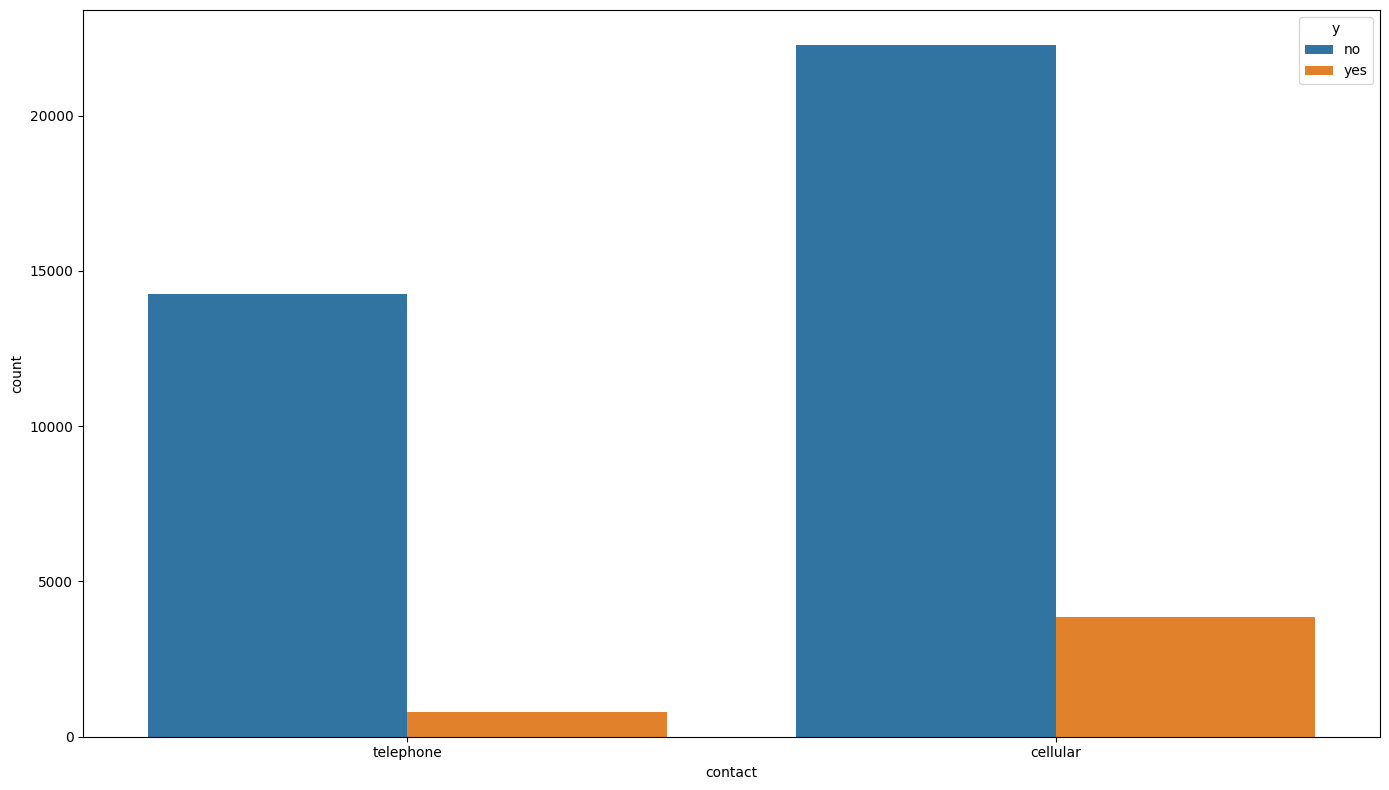

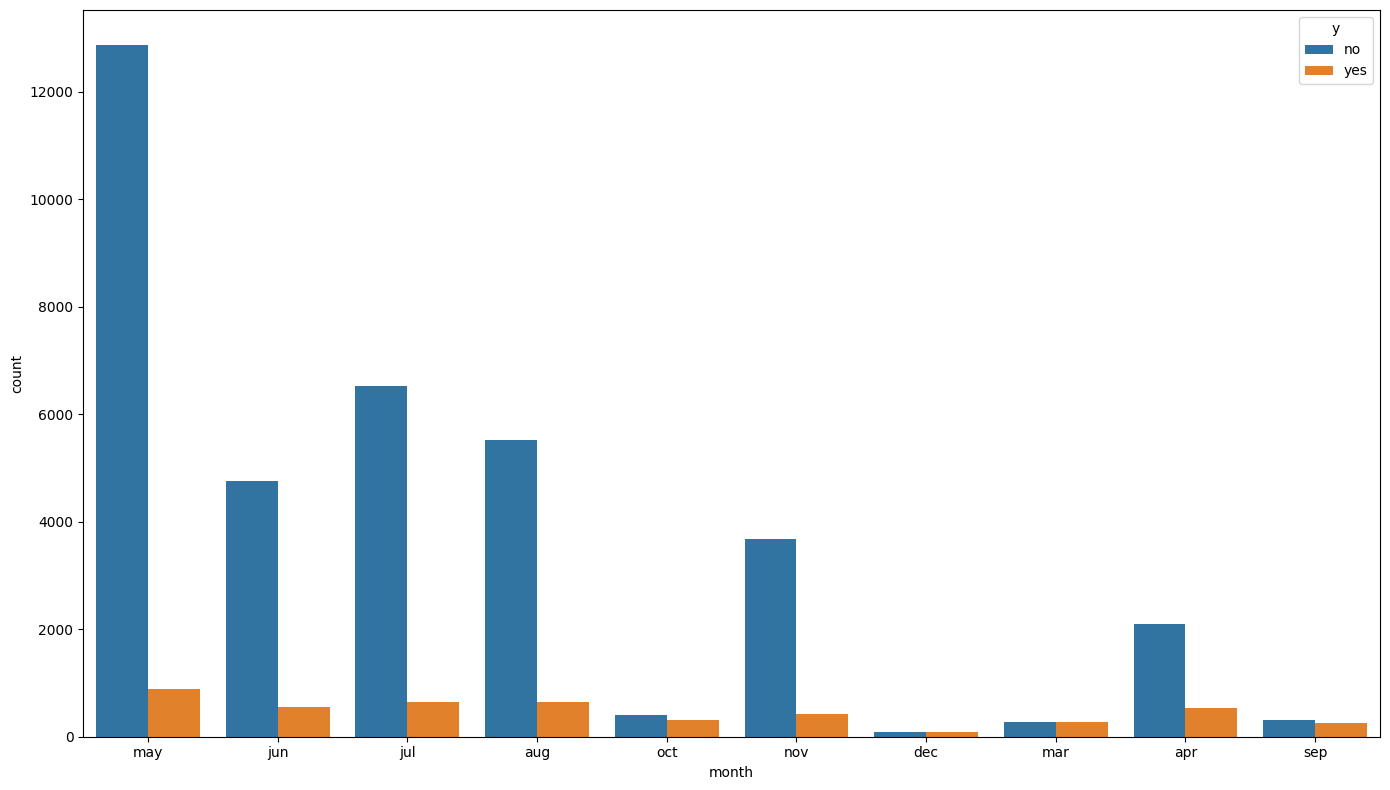

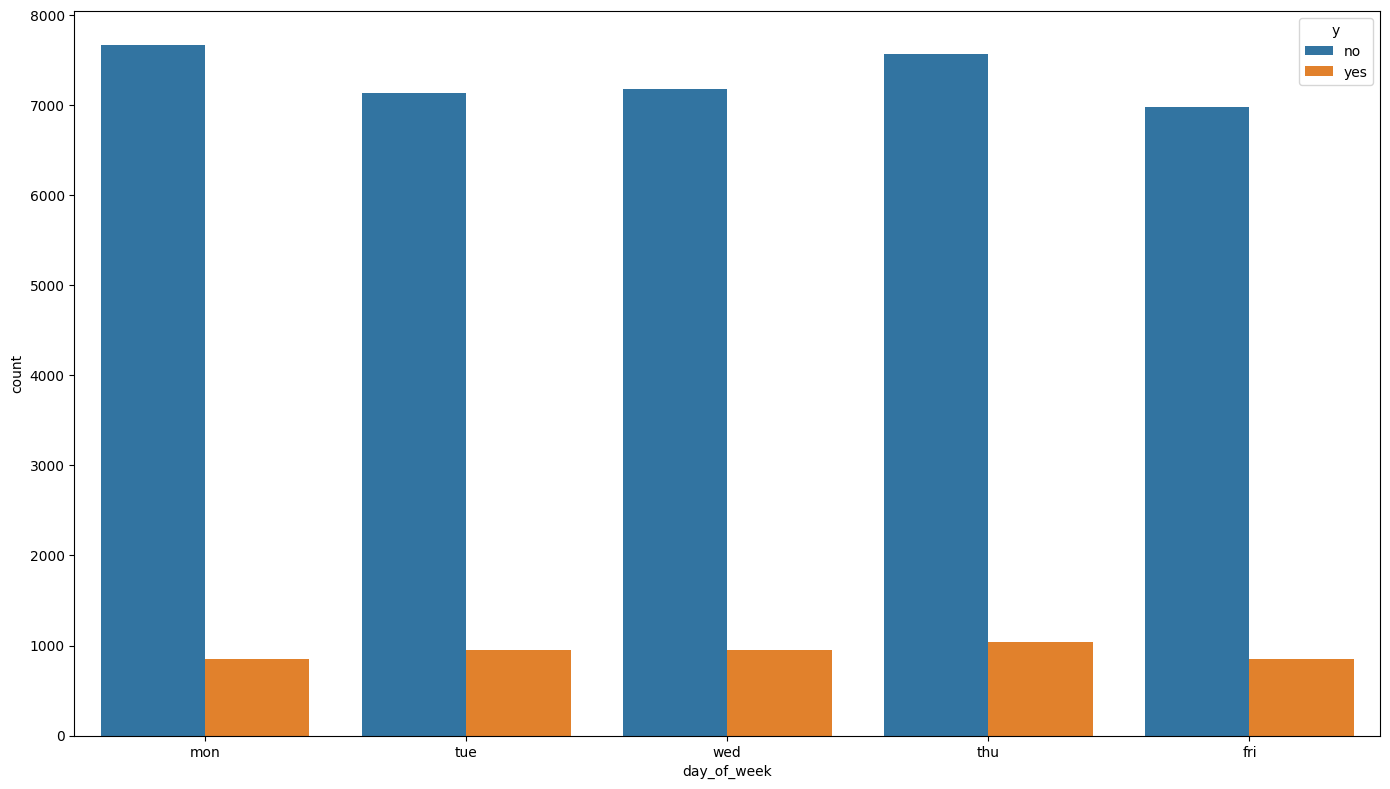

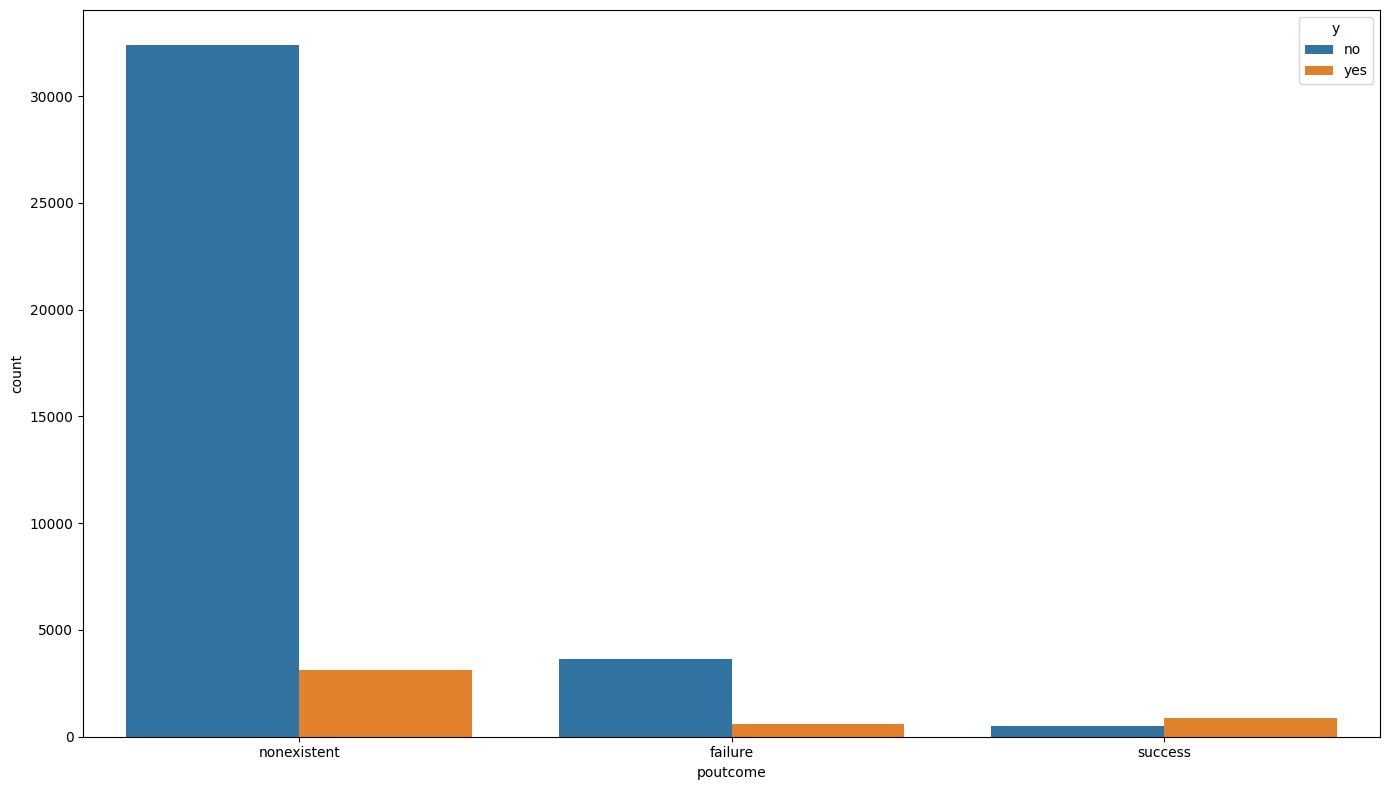

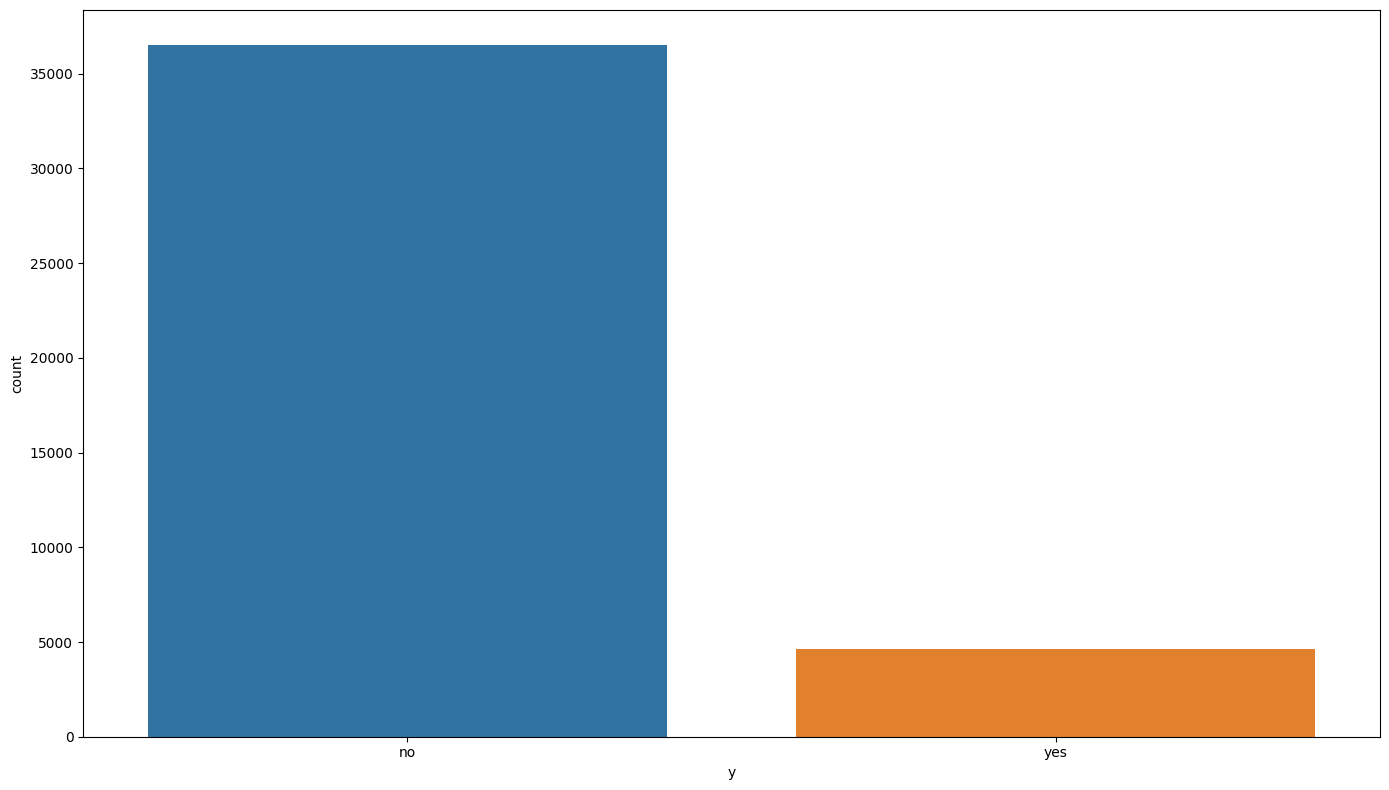

In [11]:
cat_cols = df.select_dtypes(include = ['object'])

for col in cat_cols:
    plt.figure(figsize = (14,8))
    sns.countplot(data=df, x = col, hue = 'y')
    plt.tight_layout()

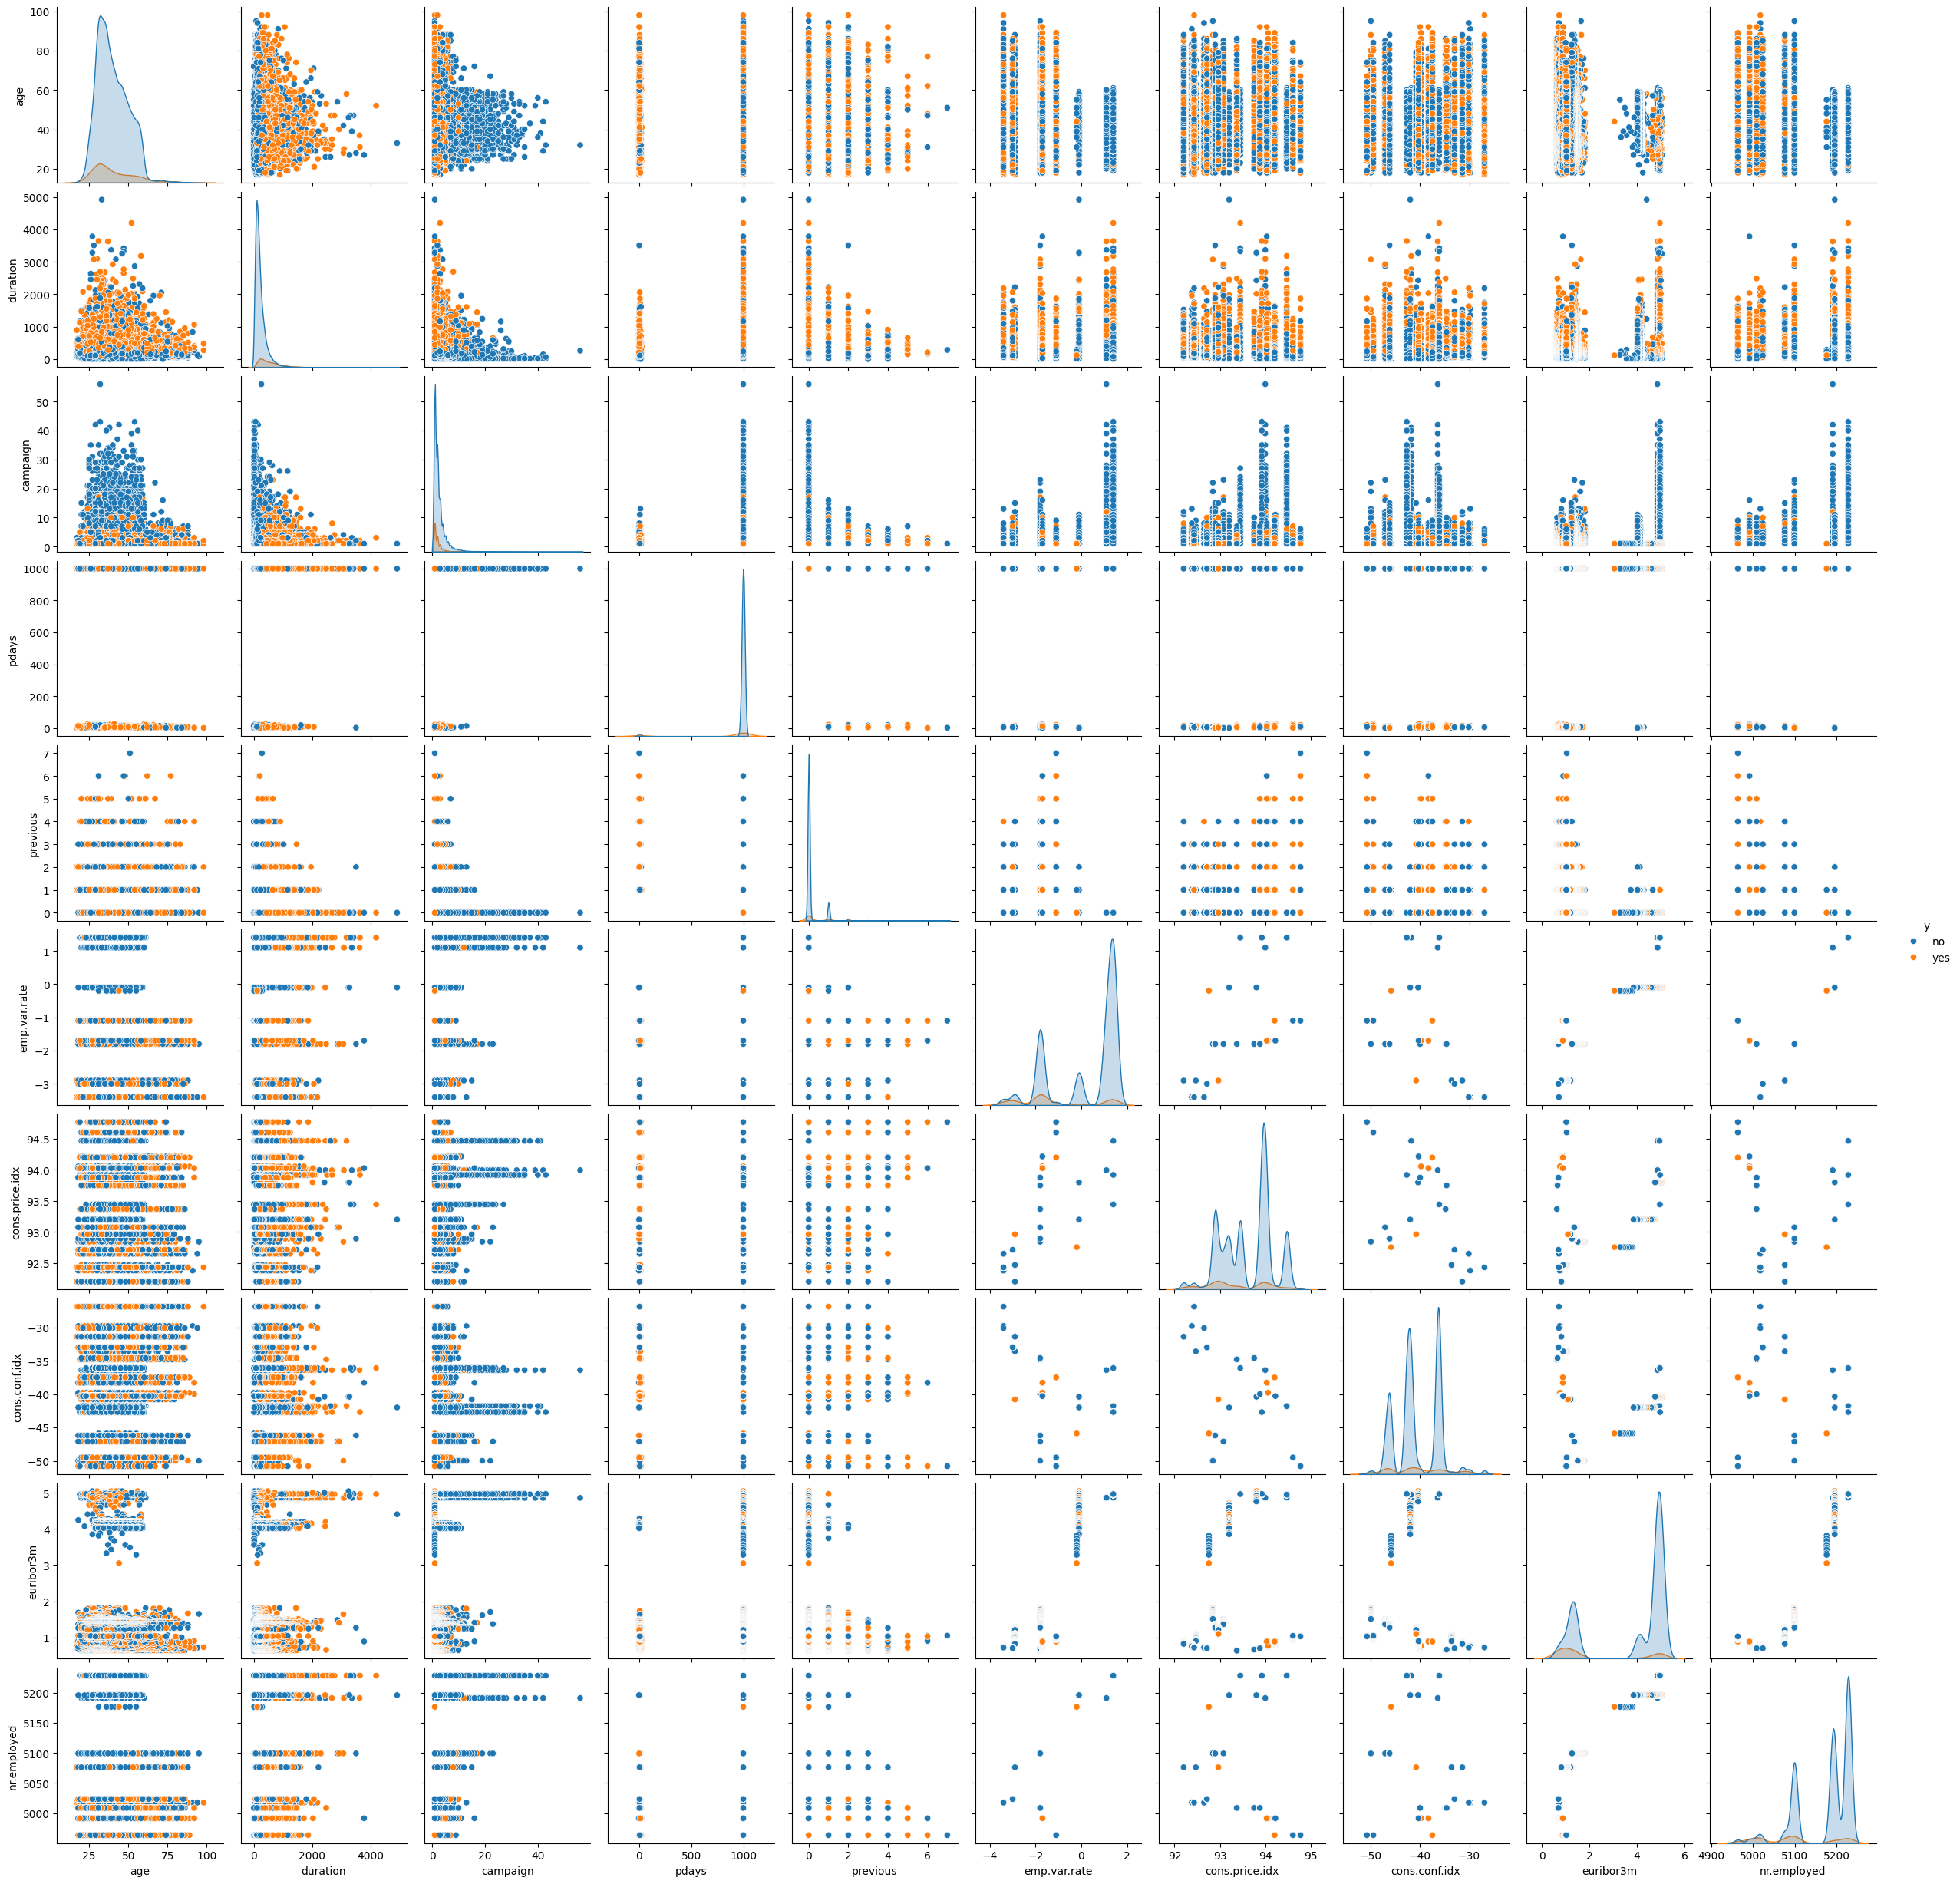

In [12]:
top_features = ['duration', 'euribor3m','nr.employed', 'age','y']
sns.pairplot(
    data = df,
    hue = 'y'
)

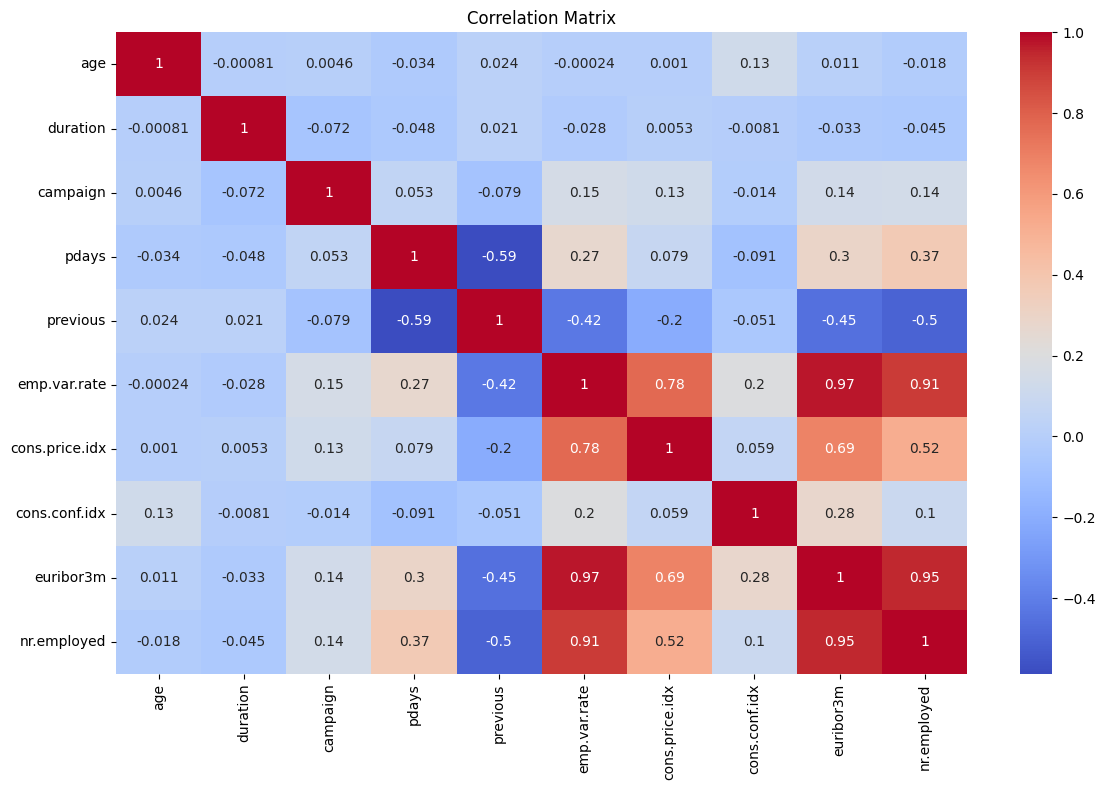

In [13]:
num_corr = num_cols.corr()

plt.figure(figsize = (12,8))
sns.heatmap(num_corr, annot = True, cmap = 'coolwarm')
plt.title('Correlation Matrix')
plt.tight_layout()

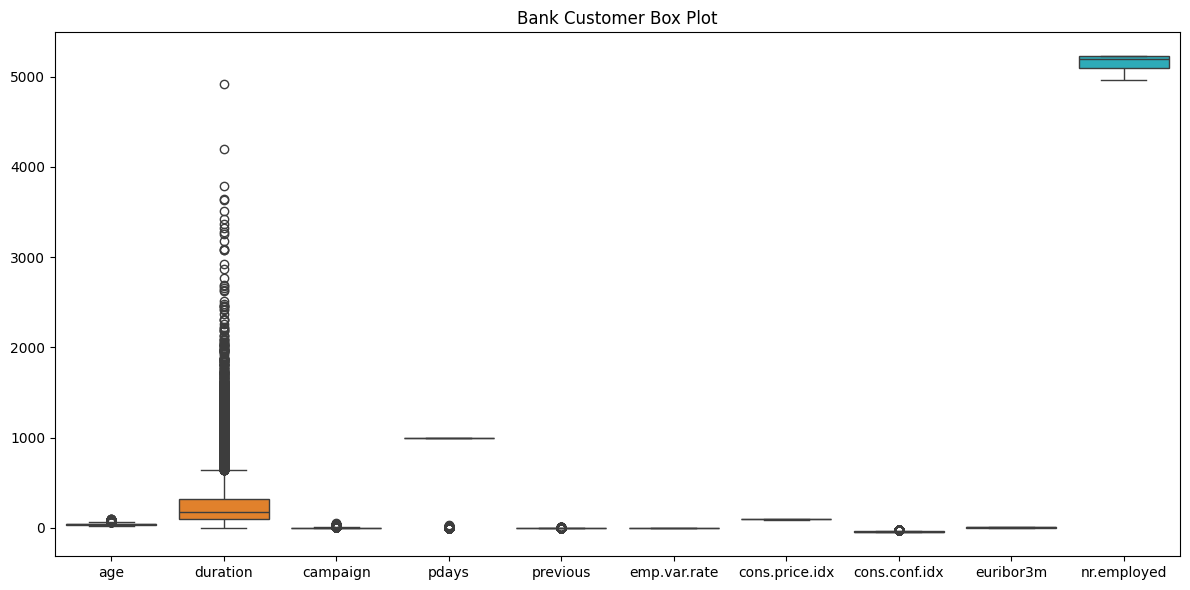

In [14]:
plt.figure(figsize =(12, 6))
sns.boxplot(data=df)
plt.title('Bank Customer Box Plot')
plt.tight_layout()

In [15]:
original_shape = df.shape

df_no_outliers = df.copy()

print("Outlier count per numerical column:\n")

for col in num_cols:
    q1 = df_no_outliers[col].quantile(0.25)
    q3 = df_no_outliers[col].quantile(0.75)
    IQR = q3 - q1

    condition = (df_no_outliers[col] < q1 - 1.5 * IQR) | (df_no_outliers[col] > q3 + 1.5 * IQR)
    outliers = condition.sum()

    print(f"{col}: {outliers} outliers")

    # Remove outliers cumulatively
    df_no_outliers = df_no_outliers[~condition]

# Compare shapes
print("\nShape Comparison:")
print(f"Original dataset shape: {original_shape}")
print(f"No-outliers dataset shape: {df_no_outliers.shape}")

Outlier count per numerical column:

age: 468 outliers
duration: 2935 outliers
campaign: 2249 outliers
pdays: 1268 outliers
previous: 3694 outliers
emp.var.rate: 1542 outliers
cons.price.idx: 0 outliers
cons.conf.idx: 0 outliers
euribor3m: 5922 outliers
nr.employed: 0 outliers

Shape Comparison:
Original dataset shape: (41176, 21)
No-outliers dataset shape: (23098, 21)


##### Data Summary
   - Clean data 
   - Many outliers
   - Unbalanced

#### Data Preprocessing

In [16]:
df_object = df.select_dtypes(include = ['object'])

for col in df_object:
    df[col] = LabelEncoder().fit_transform(df[col])

In [17]:
x = df.drop(['y'], axis = 1)
y = df['y']

In [18]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42, stratify = y)

In [19]:
smote_enn = SMOTEENN(random_state =42)
x_train, y_train = smote_enn.fit_resample(x_train, y_train)

In [20]:
sc = RobustScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

#### Machine Learning

In [21]:
lg = LogisticRegression(class_weight = 'balanced')
lg.fit(x_train, y_train)

lg_pred = lg.predict(x_test)
print('Logistic Regression:\n')
print(classification_report(y_test, lg_pred))


Logistic Regression:

              precision    recall  f1-score   support

           0       0.98      0.84      0.90      7308
           1       0.41      0.89      0.56       928

    accuracy                           0.84      8236
   macro avg       0.70      0.86      0.73      8236
weighted avg       0.92      0.84      0.87      8236



In [22]:
xgb = XGBClassifier(eval_metric = 'logloss')
xgb.fit(x_train, y_train)

xg_pred = xgb.predict(x_test)
print('XGBoost Classifier:\n')
print(classification_report(y_test, xg_pred))


XGBoost Classifier:

              precision    recall  f1-score   support

           0       0.98      0.88      0.93      7308
           1       0.48      0.88      0.62       928

    accuracy                           0.88      8236
   macro avg       0.73      0.88      0.78      8236
weighted avg       0.93      0.88      0.89      8236



### Deep Learning

#### Tensorflow

In [23]:
input_dim = x_train.shape[1]

In [24]:
# tensorflow model

tf_model = Sequential([
    Dense(64, activation = 'relu', input_dim = input_dim),
    BatchNormalization(),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation = 'sigmoid')
])

In [25]:
# compile tf model

tf_model.compile(
    optimizer = Adam(learning_rate = 0.001),
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

In [26]:
# callbacks

early_stop = EarlyStopping(monitor = 'val_loss', patience = 10, restore_best_weights = True)
reduce_lr = ReduceLROnPlateau(monitor = 'val_loss', factor = 0.5, patience = 5, min_lr = 1e-5 )

In [27]:
tf_history = tf_model.fit(
    x_train, y_train,
    validation_split = 0.2,
    epochs = 50,
    batch_size = 256,
    callbacks = [early_stop, reduce_lr],
    verbose = 1
)

Epoch 1/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8532 - loss: 0.3323 - val_accuracy: 0.8996 - val_loss: 0.2511 - learning_rate: 0.0010
Epoch 2/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9282 - loss: 0.1938 - val_accuracy: 0.9079 - val_loss: 0.2245 - learning_rate: 0.0010
Epoch 3/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9339 - loss: 0.1780 - val_accuracy: 0.9264 - val_loss: 0.1895 - learning_rate: 0.0010
Epoch 4/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9366 - loss: 0.1707 - val_accuracy: 0.9443 - val_loss: 0.1612 - learning_rate: 0.0010
Epoch 5/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9400 - loss: 0.1610 - val_accuracy: 0.9429 - val_loss: 0.1617 - learning_rate: 0.0010
Epoch 6/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9413 - loss: 0.1544 - val_accuracy: 0.9482 - val_loss: 0.1618 - learning_rate: 0.0010
Epoch 7/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9430 - loss: 0.1503 - 

In [28]:
# tf evalauation
tf_probs = tf_model.predict(x_test)
tf_pred = (tf_probs > 0.5).astype(int)

print("TensorFlow ANN:\n")
print(classification_report(y_test, tf_pred))

258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 815us/step
TensorFlow ANN:

              precision    recall  f1-score   support

           0       0.99      0.85      0.91      7308
           1       0.43      0.92      0.59       928

    accuracy                           0.85      8236
   macro avg       0.71      0.88      0.75      8236
weighted avg       0.92      0.85      0.88      8236



#### Pytorch

In [29]:
df_train, df_temp = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["y"]
)

df_valid, df_test = train_test_split(
    df_temp,
    test_size=0.5,
    random_state=42,
    stratify=df_temp["y"]
)


In [30]:
# Separate features and target
X_train_pt = df_train.drop("y", axis=1)
y_train_pt = df_train["y"]

# Apply SMOTEENN
smote_enn = SMOTEENN(random_state=42)
X_train_res, y_train_res = smote_enn.fit_resample(X_train_pt, y_train_pt)

# Rebuild dataframe for PyTorch Tabular
df_train_resampled = pd.concat(
    [pd.DataFrame(X_train_res, columns=X_train_pt.columns),
     pd.DataFrame(y_train_res, columns=["y"])],
    axis=1
)


In [31]:
data_config = DataConfig(
    target=['y'],
    continuous_cols = [
    "age", "duration", "campaign", "pdays", "previous",
    "emp.var.rate", "cons.price.idx", "cons.conf.idx",
    "euribor3m", "nr.employed"
],
      
    categorical_cols = [
    "job", "marital", "education", "default",
    "housing", "loan", "contact",
    "month", "day_of_week", "poutcome"
] 
)

In [32]:
model_config = CategoryEmbeddingModelConfig(
    task="classification",
    layers="64-32",
    activation="ReLU",
    dropout=0.3,
)

trainer_config = TrainerConfig(
    max_epochs=50,
    accelerator="gpu" if torch.cuda.is_available() else "cpu",
)

optimizer_config = OptimizerConfig()

In [33]:
tabular_model = TabularModel(
    data_config=data_config,
    model_config=model_config,
    trainer_config=trainer_config,
    optimizer_config=optimizer_config,
)

tabular_model.fit(train=df_train_resampled, validation=df_valid)


2026-02-09 08:52:50,367 - {pytorch_tabular.tabular_model:145} - INFO - Experiment Tracking is turned off
Seed set to 42
2026-02-09 08:52:50,488 - {pytorch_tabular.tabular_model:547} - INFO - Preparing the DataLoaders
2026-02-09 08:52:50,510 - {pytorch_tabular.tabular_datamodule:527} - INFO - Setting up the datamodule for classification task
2026-02-09 08:52:50,599 - {pytorch_tabular.tabular_model:598} - INFO - Preparing the Model: CategoryEmbeddingModel
2026-02-09 08:52:50,682 - {pytorch_tabular.tabular_model:341} - INFO - Preparing the Trainer
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
2026-02-09 08:52:50,717 - {pytorch_tabular.tabular_model:677} - INFO - Training Started


┏━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name             ┃ Type                      ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ _backbone        │ CategoryEmbeddingBackbone │  5.0 K │ train │     0 │
│ 1 │ _embedding_layer │ Embedding1dLayer          │    293 │ train │     0 │
│ 2 │ head             │ LinearHead                │     66 │ train │     0 │
│ 3 │ loss             │ CrossEntropyLoss          │      0 │ train │     0 │
└───┴──────────────────┴───────────────────────────┴────────┴───────┴───────┘

Trainable params: 5.3 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 5.3 K                                                                                                
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 26                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

2026-02-09 08:53:17,340 - {pytorch_tabular.tabular_model:690} - INFO - Training the model completed
2026-02-09 08:53:17,342 - {pytorch_tabular.tabular_model:1531} - INFO - Loading the best model


In [34]:
preds = tabular_model.predict(df_test)

# Extract predictions
y_pred_pt = preds["y_prediction"].values
y_true_pt = df_test["y"].values

In [35]:
# Classification report
print("PyTorch Tabular Model:\n")
print(classification_report(y_true_pt, y_pred_pt))


PyTorch Tabular Model:

              precision    recall  f1-score   support

           0       0.98      0.86      0.91      3654
           1       0.44      0.87      0.58       464

    accuracy                           0.86      4118
   macro avg       0.71      0.86      0.75      4118
weighted avg       0.92      0.86      0.88      4118



#### Tensorflow Optuna Tuning

In [36]:
def build_tf_model(trial, input_dim):

    model = Sequential()

    # Tune number of hidden layers
    n_layers = trial.suggest_int("n_layers", 1, 3)

    for i in range(n_layers):
        units = trial.suggest_int(f"units_l{i}", 16, 128)
        dropout = trial.suggest_float(f"dropout_l{i}", 0.1, 0.5)

        if i == 0:
            model.add(Dense(units, activation="relu", input_dim=input_dim))
        else:
            model.add(Dense(units, activation="relu"))

        model.add(BatchNormalization())
        model.add(Dropout(dropout))

    # Output layer
    model.add(Dense(1, activation="sigmoid"))

    # Tune learning rate
    lr = trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)

    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["AUC"]   # better for imbalanced data
    )

    return model


In [39]:
def objective(trial):

    # Proper train/validation split
    X_tr, X_val, y_tr, y_val = train_test_split(
        x_train, y_train,
        test_size=0.2,
        stratify=y_train,
        random_state=42
    )

    model = build_tf_model(trial, input_dim=X_tr.shape[1])

    batch_size = trial.suggest_categorical("batch_size", [64, 128, 256])

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=0
    )

    # Train
    model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=30,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=0
    )

    # Predict validation
    val_preds = model.predict(X_val, verbose=0)

    # Compute ROC-AUC safely
    auc = roc_auc_score(y_val, val_preds)

    return auc


In [40]:
study = optuna.create_study(direction="maximize")

study.optimize(objective, n_trials=20)

print("Best Trial Parameters:")
print(study.best_trial.params)


[I 2026-02-09 09:57:11,964] A new study created in memory with name: no-name-2003fa99-664e-4b02-9dd6-281eedb78227
[I 2026-02-09 09:57:38,316] Trial 0 finished with value: 0.9923481584838907 and parameters: {'n_layers': 3, 'units_l0': 55, 'dropout_l0': 0.3333333547810441, 'units_l1': 83, 'dropout_l1': 0.12010228228656748, 'units_l2': 94, 'dropout_l2': 0.12651938516016226, 'learning_rate': 0.0025934644570533637, 'batch_size': 128}. Best is trial 0 with value: 0.9923481584838907.
[I 2026-02-09 09:57:57,184] Trial 1 finished with value: 0.9922657466121731 and parameters: {'n_layers': 1, 'units_l0': 110, 'dropout_l0': 0.4535780145645021, 'learning_rate': 0.0015298157821946742, 'batch_size': 256}. Best is trial 0 with value: 0.9923481584838907.
[I 2026-02-09 09:58:42,556] Trial 2 finished with value: 0.9900620564907217 and parameters: {'n_layers': 3, 'units_l0': 16, 'dropout_l0': 0.1112915179332506, 'units_l1': 106, 'dropout_l1': 0.30631907610223696, 'units_l2': 26, 'dropout_l2': 0.298131562

Best Trial Parameters:
{'n_layers': 2, 'units_l0': 95, 'dropout_l0': 0.21695491441097717, 'units_l1': 74, 'dropout_l1': 0.10844345305970356, 'learning_rate': 0.0025987132991280608, 'batch_size': 128}


In [41]:
best_params = study.best_trial.params

final_model = build_tf_model(
    optuna.trial.FixedTrial(best_params),
    input_dim=x_train.shape[1]
)

early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

final_model.fit(
    x_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=best_params["batch_size"],
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
326/326 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AUC: 0.9761 - loss: 0.1955 - val_AUC: 0.0000e+00 - val_loss: 0.1708
Epoch 2/50
326/326 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - AUC: 0.9861 - loss: 0.1446 - val_AUC: 0.0000e+00 - val_loss: 0.1115
Epoch 3/50
326/326 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - AUC: 0.9878 - loss: 0.1331 - val_AUC: 0.0000e+00 - val_loss: 0.0872
Epoch 4/50
326/326 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - AUC: 0.9892 - loss: 0.1254 - val_AUC: 0.0000e+00 - val_loss: 0.0744
Epoch 5/50
326/326 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - AUC: 0.9889 - loss: 0.1261 - val_AUC: 0.0000e+00 - val_loss: 0.0912
Epoch 6/50
326/326 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - AUC: 0.9897 - loss: 0.1204 - val_AUC: 0.0000e+00 - val_loss: 0.1020
Epoch 7/50
326/326 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - AUC: 0.9899 - loss: 0.1200 - val_AUC: 0.0000e+00 - val_loss: 0.0883
Epoch 8/50
326/326 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - AUC: 0.9903 - loss: 0.1160 - val_AUC: 0.0000e+00 - val_loss: 0.0596
Epoch 9/50
326/326 ━━━━━

In [42]:
# Evaluation
tf_probs = final_model.predict(x_test)
tf_pred = (tf_probs > 0.5).astype(int)

print("Tuned TensorFlow ANN:\n")
print(classification_report(y_test, tf_pred))

258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Tuned TensorFlow ANN:

              precision    recall  f1-score   support

           0       0.99      0.84      0.91      7308
           1       0.43      0.93      0.59       928

    accuracy                           0.85      8236
   macro avg       0.71      0.88      0.75      8236
weighted avg       0.93      0.85      0.87      8236

